<a href="https://colab.research.google.com/github/govardhansnair/Monte-Carlo-Option-Pricing/blob/main/01_Monte_Carlo_Model_Concept.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
Z=np.random.normal(0,1,10)
print(Z)

[-0.92554324 -0.10243271  0.70587906  1.16709628 -2.03626064 -1.39993564
 -1.5239412  -0.18968168 -0.03313134 -0.2953476 ]


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# Model parameters
S0 = 100
K = 100
r = 0.05
sigma = 0.20
T = 1.0
N = 100000

# Reproducibility
np.random.seed(42)

# Generate standard normal random variables

Z = np.random.normal(0, 1, N)

# Simulating terminal stock prices
ST=S0*np.exp((r-0.5*sigma**2)*T+sigma*np.sqrt(T)*Z)

#Calculate option payoffs

call_payoffs=np.maximum(ST-K,0)
put_payoffs=np.maximum(K-ST,0)

# Discount factor
discount_factor=np.exp(-r*T)

# Monte Carlo prices

call_price_MC=discount_factor*np.mean(call_payoffs)

put_price_MC=discount_factor*np.mean(put_payoffs)

print("MONTE CARLO OPTION PRICES")

print(f"European Call: £{call_price_MC:.4f}")
print(f"European Put:  £{put_price_MC:.4f}")


print("First 10 call payoffs:")
print(call_payoffs[:10])

print("First 10 put payoffs:")
print(put_payoffs[:10])

print("\nAverage Call Payoff:", np.mean(call_payoffs))
print("Average Put Payoff:", np.mean(put_payoffs))

print("First 10 simulated stock prices:")
print(ST[:10])

print("Average simulated stock price:", np.mean(ST))
print("Minimum stock price:", np.min(ST))
print("Maximum stock price:", np.max(ST))

print("First 10 random values:")
print(Z[:10])

print("Mean:", np.mean(Z))
print("Standard Deviation:", np.std(Z))



print("Stock Price:", S0)
print("Strike Price:", K)
print("Risk-Free Rate:", r)
print("Volatility:", sigma)
print("Time to Expiry:", T)
print("Simulations:", N)


MONTE CARLO OPTION PRICES
European Call: £10.4739
European Put:  £5.5742
First 10 call payoffs:
[13.8080226   0.23498965 17.29684912 39.73896651  0.          0.
 41.31801116 20.1399282   0.         14.85634743]
First 10 put payoffs:
[0.         0.         0.         0.         1.66898304 1.66866017
 0.         0.         6.18963896 0.        ]

Average Call Payoff: 11.010899884851826
Average Put Payoff: 5.859980249174256
First 10 simulated stock prices:
[113.8080226  100.23498965 117.29684912 139.73896651  98.33101696
  98.33133983 141.31801116 120.1399282   93.81036104 114.85634743]
Average simulated stock price: 105.15091963567757
Minimum stock price: 42.18435481340032
Maximum stock price: 252.3929090544177
First 10 random values:
[ 0.49671415 -0.1382643   0.64768854  1.52302986 -0.23415337 -0.23413696
  1.57921282  0.76743473 -0.46947439  0.54256004]
Mean: 0.0009668681409495966
Standard Deviation: 1.0009009542948903
Stock Price: 100
Strike Price: 100
Risk-Free Rate: 0.05
Volatility:

In [ ]:
# Discount individual payoff
discounted_call=discount_factor*call_payoffs
discounted_put=discount_factor*put_payoffs

# Standard errors
call_SE=np.std(discounted_call,ddof=1)/np.sqrt(N)
put_SE=np.std(discounted_put,ddof=1)/np.sqrt(N)

# 95% confidence intervals

call_CI=(call_price_MC-1.96*call_SE,call_price_MC+1.96*call_SE)

put_CI=(put_price_MC-1.96*put_SE,put_price_MC+1.96*put_SE)

print("CALL OPTION")
print("Price:", call_price_MC)
print("Standard Error:", call_SE)
print("95% Confidence Interval:", call_CI)

print("\nPUT OPTION")
print("Price:", put_price_MC)
print("Standard Error:", put_SE)
print("95% Confidence Interval:", put_CI)


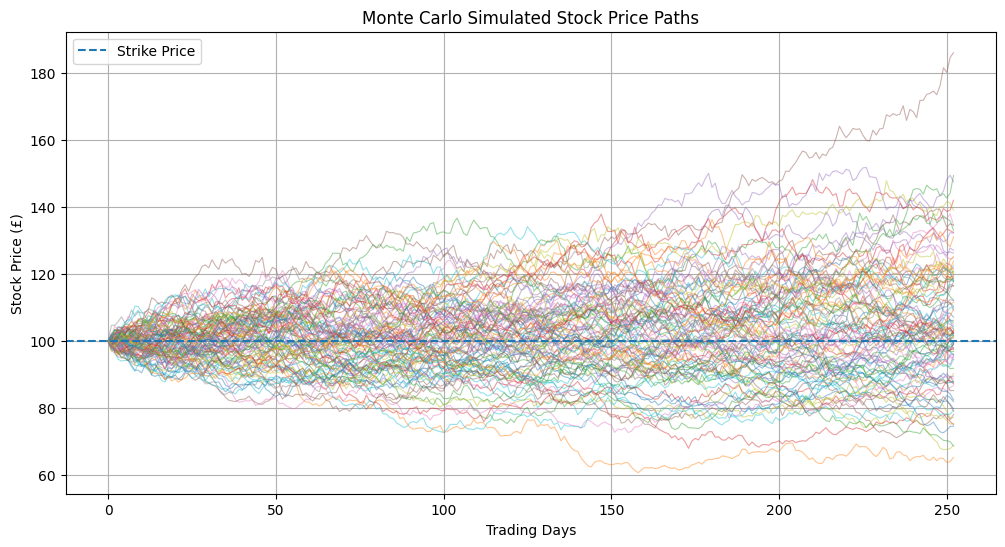

In [ ]:
#Visualisation

# Path simulation settings

steps=252
paths=100

dt =T/steps

# Generate random shocks for each path and time step

Z_paths=np.random.normal(0,1,(paths, steps))

# Initialise stock price matrix

stock_paths = np.zeros((paths, steps + 1))

stock_paths[:, 0]=S0

# Simulate paths

for t in range(steps):
  stock_paths[:,t+1]=stock_paths[:,t]*np.exp((r-0.5*sigma**2)*dt+sigma*np.sqrt(dt)
  *Z_paths[:,t])

# Plot

plt.figure(figsize=(12,6))

for i in range(paths):
    plt.plot(stock_paths[i],alpha=0.45,linewidth=0.8)

plt.axhline(K, linestyle="--", label="Strike Price")

plt.title("Monte Carlo Simulated Stock Price Paths")
plt.xlabel("Trading Days")
plt.ylabel("Stock Price (£)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Comparing outputs with Black Scholes Model

# Black-Scholes calculation

d1=(np.log(S0/K)+(r+0.5*sigma**2)*T)/(sigma*np.sqrt(T))

d2=d1-sigma*np.sqrt(T)

# Call price

call_BS=(S0*norm.cdf(d1)-K*np.exp(-r*T)*norm.cdf(d2))

# Put price

put_BS=(K*np.exp(-r*T)*norm.cdf(-d2)-S0*norm.cdf(-d1))

# Comparison table

comparison = pd.DataFrame({"Model": ["Monte Carlo", "Black-Scholes"],
                           "Call Price": [call_price_MC, call_BS],
                           "Put Price": [put_price_MC, put_BS]})

print(comparison)

print("\nAbsolute Pricing Errors")
print("Call:", abs(call_price_MC - call_BS))
print("Put:", abs(put_price_MC - put_BS))





           Model  Call Price  Put Price
0    Monte Carlo   10.473892   5.574186
1  Black-Scholes   10.450584   5.573526

Absolute Pricing Errors
Call: 0.023308388517016
Put: 0.0006596177506068557


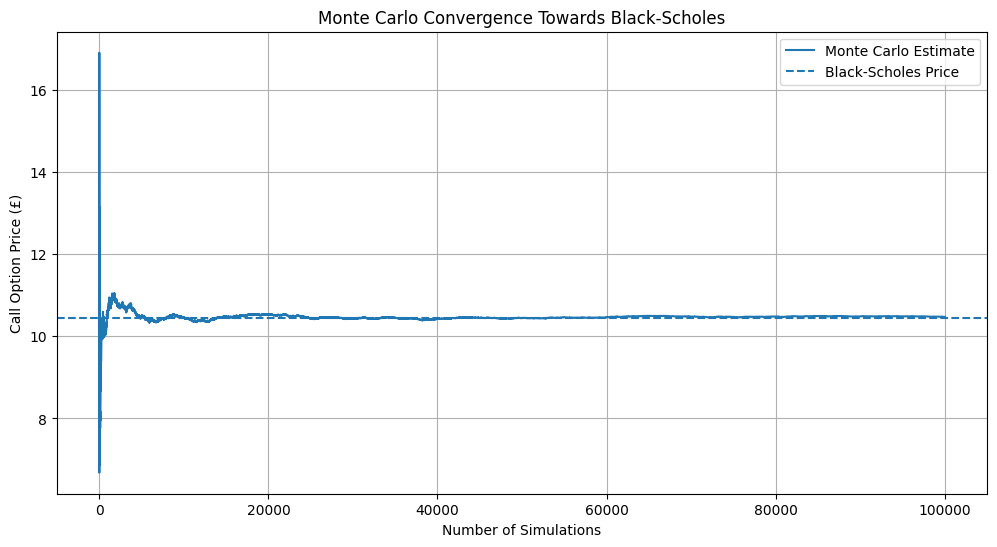

In [ ]:
# Visualisation
discounted_call=discount_factor*call_payoffs
discounted_put=discount_factor*put_payoffs

# Calculate cumulative Monte Carlo estimates

cumulative_payoffs=np.cumsum(discounted_call)

simulation_numbers=np.arange(1, N + 1)

running_prices=cumulative_payoffs / simulation_numbers

# Plot convergence

plt.figure(figsize=(12, 6))

plt.plot(simulation_numbers,running_prices,label="Monte Carlo Estimate")

plt.axhline(call_BS,linestyle="--",label="Black-Scholes Price")

plt.xlabel("Number of Simulations")
plt.ylabel("Call Option Price (£)")
plt.title("Monte Carlo Convergence Towards Black-Scholes")
plt.legend()
plt.grid(True)
plt.show()



In [ ]:
# To reduce the Variance, use antithetic values

call_SE=np.std(discounted_call,ddof=1)/np.sqrt(N)
put_SE=np.std(discounted_put,ddof=1)/np.sqrt(N)

# Generate half the required random numbers

N_half = 50000

Z_half = np.random.normal(0, 1, N_half)

# Generate paired simulations

Z_anti = np.concatenate([Z_half, -Z_half])

# Simulate stock prices

ST_anti = S0 * np.exp(
    (r - 0.5*sigma**2)*T
    + sigma*np.sqrt(T)*Z_anti
)

# Calculate discounted call payoffs

payoff_anti = np.exp(-r*T) * np.maximum(ST_anti-K, 0)

# Calculate price and standard error

call_anti = np.mean(payoff_anti)

SE_anti = np.std(payoff_anti, ddof=1) / np.sqrt(2*N_half)

print("Standard Monte Carlo:", call_price_MC)
print("Antithetic Monte Carlo:", call_anti)

print("Standard MC SE:", call_SE)
print("Antithetic MC SE:", SE_anti)


Standard Monte Carlo: 10.47389196070258
Antithetic Monte Carlo: 10.464233170894481
Standard MC SE: 0.04658930684614377
Antithetic MC SE: 0.046599397763529796
